# ¿Puede comprobarse que el algoritmo de Michigan será un 30 % más preciso?

## Un EDA sobre lo que cuenta la precisión y lo que deja fuera

> **Pregunta:** ¿basta una mejora global de precisión para saber si un sistema de clasificación penitenciaria tomará mejores decisiones?

**Categoría obligatoria: EDA (análisis exploratorio de datos).**

Michigan anunció un nuevo sistema para clasificar a personas encarceladas según su riesgo de violencia dentro de prisión. Afirma que mejorará la capacidad predictiva alrededor de un 30 %, pero no ha publicado el modelo, sus datos de validación, la métrica, el punto de comparación ni los resultados por grupos. Por eso no intento reproducir ni auditar ese sistema.

Utilizo una base pública distinta, la de COMPAS en el condado de Broward (Florida), como **ejemplo didáctico**. Mi objetivo es observar cómo una misma puntuación produce errores diferentes cuando cambio el umbral y cuando separo grupos. No entreno ningún modelo ni genero una predicción propia.

## Ruta de lectura

1. Compruebo qué afirma Michigan y qué información falta.
2. Explico qué representa cada fila de la base pública de COMPAS.
3. Reproduzco el filtro documentado por ProPublica.
4. Convierto las puntuaciones en decisiones con varios umbrales.
5. Comparo los dos tipos de error.
6. Compruebo si una precisión parecida oculta errores repartidos de manera distinta.
7. Separo lo que este ejemplo enseña de lo que no permite afirmar sobre Michigan.

### Glosario breve

- **Umbral:** nota mínima a partir de la cual considero una puntuación de riesgo como “alta”.
- **Falso positivo:** la puntuación marca riesgo alto, pero la reincidencia observada no ocurre durante los dos años siguientes.
- **Falso negativo:** la puntuación marca riesgo bajo, pero sí se observa reincidencia.
- **Precisión global:** porcentaje total de clasificaciones que coinciden con el resultado observado.
- **Tasa de falsos positivos:** falsos positivos entre quienes no reincidieron.
- **Tasa de falsos negativos:** falsos negativos entre quienes sí reincidieron.

## 1. La afirmación que no puede auditarse todavía

El Departamento de Prisiones de Michigan anunció el 28 de octubre de 2026 que probará el sistema desde el 1 de diciembre en varias prisiones masculinas. Dice que espera mejorar alrededor de un 30 % la capacidad de predecir violencia futura.

La nota oficial no publica cinco piezas imprescindibles para interpretar esa cifra:

| Pieza necesaria | ¿Está publicada? |
|---|---:|
| definición exacta de “violencia futura” | No |
| periodo durante el que se observa el resultado | No |
| métrica que mejora un 30 % | No |
| resultado del sistema anterior usado como referencia | No |
| falsos positivos y falsos negativos, también por grupos | No |

Además, la herramienta de Recidiviz describe flujos de clasificación, revisiones y anulaciones humanas. No basta para conocer el modelo concreto de Michigan. Mi primera conclusión documental es limitada pero firme: **el 30 % es una expectativa oficial, no un resultado público reproducible**.

In [1]:
# importo las herramientas que necesito para leer, calcular y visualizar
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# localizo el proyecto aunque ejecute el notebook desde otra carpeta
project_root = Path.cwd()
if not (project_root / "datos" / "compas-scores-two-years.csv").exists():
    project_root = Path(".").resolve()

data_path = project_root / "datos" / "compas-scores-two-years.csv"
output_path = project_root / "resultados"
output_path.mkdir(exist_ok=True)

# fijo los colores editoriales que usaré en todos los gráficos
color_nebula = "#446ddf"
color_error_alto = "#d95f59"
color_error_bajo = "#e7a33e"
color_neutro = "#aeb8cc"
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

## 2. De dónde salen los datos del ejemplo

ProPublica obtuvo mediante registros públicos puntuaciones COMPAS asignadas en 2013 y 2014 y las cruzó con expedientes judiciales del condado de Broward. El archivo descargado contiene 7.214 filas y 53 columnas.

- Cada **fila** representa una evaluación de una persona acusada en Broward.
- `decile_score` es la puntuación general de riesgo, de 1 a 10.
- `two_year_recid` indica si ProPublica observó una nueva infracción durante dos años.
- `race` recoge la clasificación racial de los registros de la oficina del sheriff.

No son personas encarceladas en Michigan, el periodo es distinto y COMPAS no es el nuevo modelo de Recidiviz. Este archivo sirve para demostrar el problema de las métricas, no para trasladar sus porcentajes a Michigan.

In [2]:
# cargo el archivo original sin modificarlo
compas_raw = pd.read_csv(data_path)

# resumo el tamaño y las variables imprescindibles antes de filtrar
resumen_origen = pd.DataFrame({
    "medida": ["filas originales", "columnas", "puntuación mínima", "puntuación máxima"],
    "valor": [len(compas_raw), len(compas_raw.columns), compas_raw["decile_score"].min(), compas_raw["decile_score"].max()],
})
display(resumen_origen)

,medida,valor
0,filas originales,7214
1,columnas,53
2,puntuación mínima,1
3,puntuación máxima,10


## 3. Reproduzco el filtro de ProPublica

Mantengo evaluaciones realizadas dentro de los 30 días anteriores o posteriores al arresto, retiro casos sin resultado de reincidencia, cargos ordinarios y puntuaciones no disponibles. Es la selección documentada por ProPublica para su muestra de dos años.

Antes de analizar compruebo que quedan 6.172 filas, que las puntuaciones están entre 1 y 10 y que el resultado observado solo contiene 0 y 1.

In [3]:
# aplico los criterios publicados para hacer comparable la muestra
compas = compas_raw.loc[
    compas_raw["days_b_screening_arrest"].between(-30, 30)
    & compas_raw["is_recid"].ne(-1)
    & compas_raw["c_charge_degree"].ne("O")
    & compas_raw["score_text"].ne("N/A")
].copy()

# verifico tamaño, duplicados del identificador y dominios básicos
comprobaciones = pd.DataFrame({
    "comprobación": [
        "filas después del filtro",
        "identificadores duplicados",
        "puntuaciones fuera de 1 a 10",
        "resultados distintos de 0 y 1",
        "valores ausentes en las variables usadas",
    ],
    "resultado": [
        len(compas),
        int(compas["id"].duplicated().sum()),
        int((~compas["decile_score"].between(1, 10)).sum()),
        int((~compas["two_year_recid"].isin([0, 1])).sum()),
        int(compas[["decile_score", "two_year_recid", "race"]].isna().sum().sum()),
    ],
})
display(comprobaciones)

assert len(compas) == 6172
assert set(compas["two_year_recid"].unique()) <= {0, 1}
assert compas["decile_score"].between(1, 10).all()

,comprobación,resultado
0,filas después del filtro,6172
1,identificadores duplicados,0
2,puntuaciones fuera de 1 a 10,0
3,resultados distintos de 0 y 1,0
4,valores ausentes en las variables usadas,0


### Qué deja la limpieza

La muestra reproduce las 6.172 evaluaciones descritas por ProPublica. Hay 2.809 casos con reincidencia observada durante los dos años siguientes y 3.363 sin ella. Este equilibrio importa: llamar a todo el mundo “riesgo alto” detectaría todos los casos de reincidencia, pero se equivocaría con las 3.363 personas restantes.

In [4]:
# cuento los dos resultados observados para no confundir puntuación con realidad
resultados_observados = (
    compas["two_year_recid"]
    .value_counts()
    .rename(index={0: "no reincidió", 1: "sí reincidió"})
    .rename_axis("resultado a dos años")
    .reset_index(name="personas")
)
display(resultados_observados)

,resultado a dos años,personas
0,no reincidió,3363
1,sí reincidió,2809


## 4. El umbral transforma una puntuación en una decisión

Una nota de 1 a 10 no decide nada por sí sola. La decisión aparece cuando alguien fija el corte. Con umbral 5, las notas 5 a 10 se consideran riesgo alto; con umbral 8, solo 8 a 10.

Para cada corte calculo precisión global y los dos errores. No busco un umbral “correcto”: quiero mostrar que cada elección cambia quién paga el coste del fallo.

In [5]:
# convierto cada posible umbral en una tabla de aciertos y errores observados
filas_umbrales = []
y_real = compas["two_year_recid"].eq(1)

for umbral in range(1, 11):
    riesgo_alto = compas["decile_score"].ge(umbral)
    verdaderos_positivos = int((riesgo_alto & y_real).sum())
    verdaderos_negativos = int((~riesgo_alto & ~y_real).sum())
    falsos_positivos = int((riesgo_alto & ~y_real).sum())
    falsos_negativos = int((~riesgo_alto & y_real).sum())

    filas_umbrales.append({
        "umbral": umbral,
        "precisión_global": (verdaderos_positivos + verdaderos_negativos) / len(compas),
        "tasa_falsos_positivos": falsos_positivos / (falsos_positivos + verdaderos_negativos),
        "tasa_falsos_negativos": falsos_negativos / (falsos_negativos + verdaderos_positivos),
        "personas_marcadas_riesgo_alto": int(riesgo_alto.sum()),
        "falsos_positivos": falsos_positivos,
        "falsos_negativos": falsos_negativos,
    })

metricas_umbrales = pd.DataFrame(filas_umbrales)
metricas_umbrales.to_csv(output_path / "metricas_umbrales.csv", index=False)
display(metricas_umbrales.round(3))

,umbral,precisión_global,tasa_falsos_positivos,tasa_falsos_negativos,personas_marcadas_riesgo_alto,falsos_positivos,falsos_negativos
0,1,0.455,1.000,0.000,6172,3363,0
1,2,0.574,0.700,0.099,4886,2354,277
2,3,0.621,0.534,0.193,4064,1796,541
3,4,0.647,0.414,0.279,3417,1393,785
4,5,0.661,0.303,0.383,2751,1018,1076
5,6,0.664,0.213,0.483,2169,716,1356
6,7,0.650,0.147,0.592,1640,495,1664
7,8,0.634,0.088,0.698,1144,297,1962
8,9,0.604,0.053,0.806,724,179,2264
9,10,0.575,0.018,0.913,304,59,2564


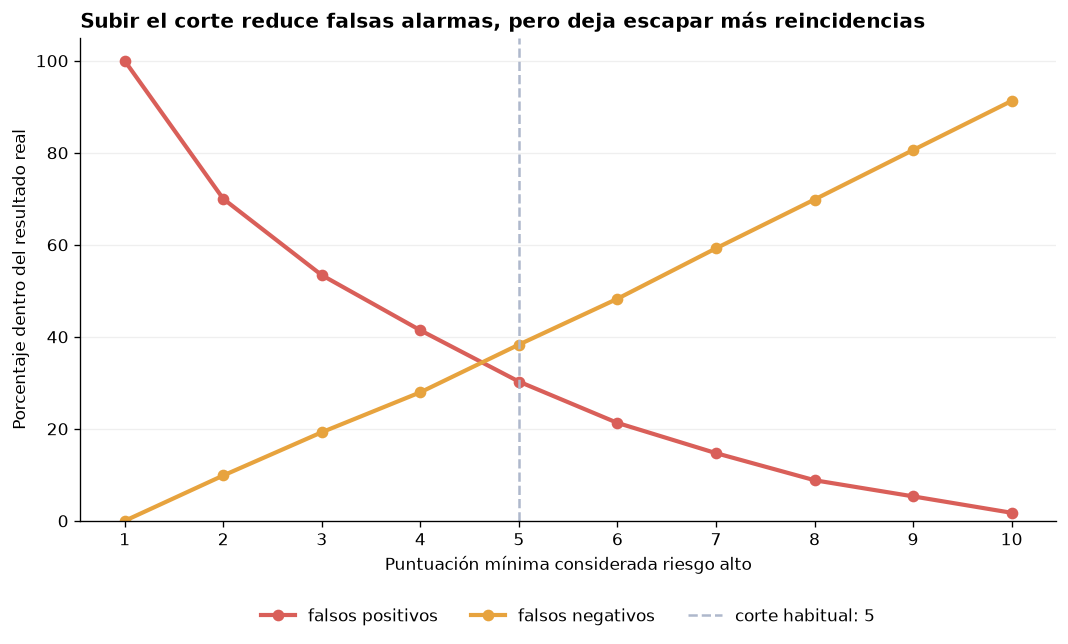

In [6]:
# dibujo cómo al reducir un error aumenta el otro
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(metricas_umbrales["umbral"], metricas_umbrales["tasa_falsos_positivos"] * 100,
        marker="o", linewidth=2.5, color=color_error_alto, label="falsos positivos")
ax.plot(metricas_umbrales["umbral"], metricas_umbrales["tasa_falsos_negativos"] * 100,
        marker="o", linewidth=2.5, color=color_error_bajo, label="falsos negativos")
ax.axvline(5, color=color_neutro, linestyle="--", linewidth=1.5, label="corte habitual: 5")
ax.set_title("Subir el corte reduce falsas alarmas, pero deja escapar más reincidencias", loc="left", weight="bold")
ax.set_xlabel("Puntuación mínima considerada riesgo alto")
ax.set_ylabel("Porcentaje dentro del resultado real")
ax.set_xticks(range(1, 11))
ax.set_ylim(0, 105)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### La decisión nunca elimina el coste: lo desplaza

Con el corte en 5, el 66,1 % de las clasificaciones coincide con el resultado observado. Aparecen **1.018 falsos positivos** y **1.076 falsos negativos**.

Si subo el corte a 8, los falsos positivos bajan a 297, pero los falsos negativos suben a 1.962. La precisión global cae al 63,4 %. La pregunta no es únicamente qué cifra es mayor, sino qué error se considera tolerable y quién soporta sus consecuencias.

## 5. Una precisión parecida puede esconder errores opuestos

Ahora mantengo el corte en 5, la frontera entre la categoría baja y las categorías media y alta de COMPAS. Comparo los dos grupos con muestra suficiente que centraron la investigación original: personas clasificadas como negras y blancas en los registros de Broward.

No interpreto “raza” como una causa biológica del resultado. Es una categoría administrativa atravesada por diferencias históricas y sociales, y la propia base puede contener errores de registro.

In [7]:
# calculo las mismas métricas por grupo con un único umbral para evitar comparaciones cambiantes
filas_grupos = []
for grupo in ["African-American", "Caucasian"]:
    datos_grupo = compas.loc[compas["race"].eq(grupo)].copy()
    real_grupo = datos_grupo["two_year_recid"].eq(1)
    alto_grupo = datos_grupo["decile_score"].ge(5)
    vp = int((alto_grupo & real_grupo).sum())
    vn = int((~alto_grupo & ~real_grupo).sum())
    fp = int((alto_grupo & ~real_grupo).sum())
    fn = int((~alto_grupo & real_grupo).sum())

    filas_grupos.append({
        "grupo_en_registro": grupo,
        "personas": len(datos_grupo),
        "precisión_global": (vp + vn) / len(datos_grupo),
        "tasa_falsos_positivos": fp / (fp + vn),
        "tasa_falsos_negativos": fn / (fn + vp),
        "falsos_positivos": fp,
        "falsos_negativos": fn,
    })

metricas_grupos = pd.DataFrame(filas_grupos)
metricas_grupos.to_csv(output_path / "metricas_grupos.csv", index=False)
display(metricas_grupos.round(3))

,grupo_en_registro,personas,precisión_global,tasa_falsos_positivos,tasa_falsos_negativos,falsos_positivos,falsos_negativos
0,African-American,3175,0.649,0.423,0.285,641,473
1,Caucasian,2103,0.672,0.220,0.496,282,408


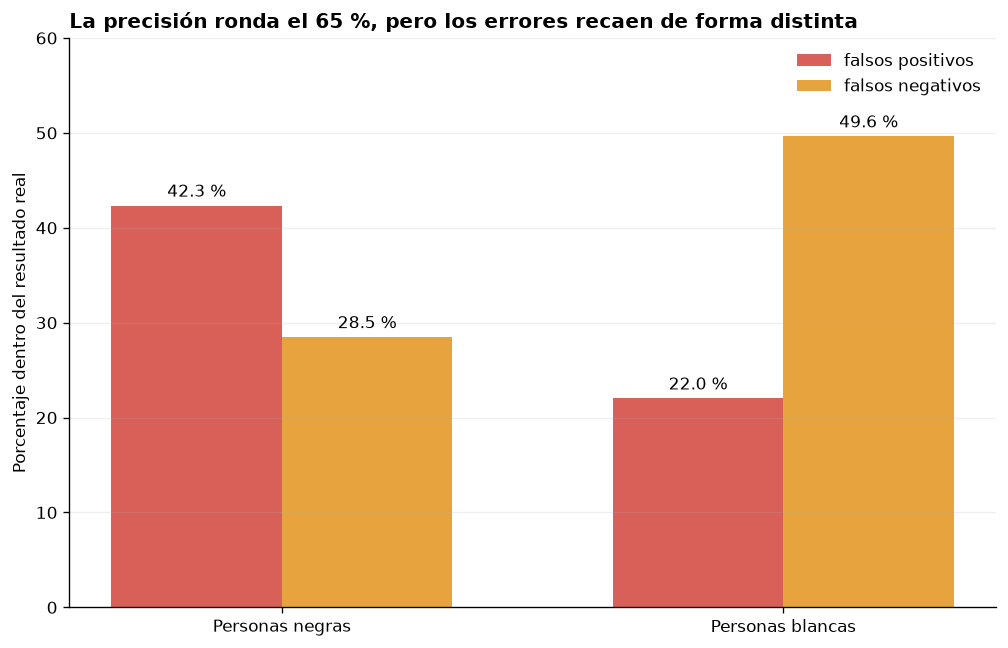

In [8]:
# comparo los errores en porcentaje porque los grupos no tienen el mismo tamaño
grafico_grupos = metricas_grupos.copy()
grafico_grupos["grupo_en_registro"] = grafico_grupos["grupo_en_registro"].map({
    "African-American": "Personas negras",
    "Caucasian": "Personas blancas",
})

x = np.arange(len(grafico_grupos))
ancho = 0.34
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.bar(x - ancho / 2, grafico_grupos["tasa_falsos_positivos"] * 100, ancho,
       color=color_error_alto, label="falsos positivos")
ax.bar(x + ancho / 2, grafico_grupos["tasa_falsos_negativos"] * 100, ancho,
       color=color_error_bajo, label="falsos negativos")
ax.set_title("La precisión ronda el 65 %, pero los errores recaen de forma distinta", loc="left", weight="bold")
ax.set_ylabel("Porcentaje dentro del resultado real")
ax.set_xticks(x, grafico_grupos["grupo_en_registro"])
ax.set_ylim(0, 60)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f %%", padding=3)

plt.tight_layout()
plt.show()

### El promedio no cuenta quién recibe cada error

La precisión global es parecida: **64,9 %** para las personas negras y **67,2 %** para las blancas. Esa cercanía desaparece al abrir la caja:

- entre quienes no reincidieron, el falso positivo alcanza el **42,3 %** en las personas negras y el **22,0 %** en las blancas;
- entre quienes sí reincidieron, el falso negativo es del **28,5 %** en las personas negras y del **49,6 %** en las blancas.

Una sola cifra permite decir que el rendimiento es semejante. Las tasas de error muestran que el sistema se equivoca de maneras casi opuestas. Este resultado reproduce el núcleo descriptivo publicado por ProPublica; no prueba por sí solo por qué se produce la diferencia ni demuestra discriminación individual.

## 6. Comprobaciones de robustez y límites

### Lo que compruebo

- La muestra filtrada coincide con las 6.172 evaluaciones documentadas.
- Los resultados del corte 5 reproducen aproximadamente las tasas difundidas por ProPublica.
- El patrón no depende de un único porcentaje agregado: aparece al contar casos y al calcular tasas sobre sus denominadores correctos.

### Lo que no puedo concluir

1. **No audito Michigan.** No dispongo del modelo, sus variables ni sus resultados de validación.
2. **No comparo tareas idénticas.** COMPAS estima reincidencia después de una evaluación judicial; Michigan pretende clasificar riesgo de violencia dentro de prisión.
3. **No pruebo causalidad.** Las diferencias entre grupos pueden recoger desigualdades previas, decisiones policiales, errores de registro y otros factores.
4. **El resultado observado tampoco es una verdad perfecta.** ProPublica estimó errores de emparejamiento en los expedientes y “reincidencia” depende de qué hechos llegan al sistema judicial.
5. **No elijo un umbral óptimo.** Elegirlo es una decisión de política pública sobre costes humanos, no una operación puramente matemática.

## 7. Conclusión

No puedo confirmar que el sistema de Michigan sea un 30 % más preciso. La Administración ha publicado una promesa sin la información necesaria para reconstruirla: falta saber qué métrica mejora, frente a qué referencia, con qué definición de violencia y cómo se reparten los errores.

El ejemplo de COMPAS explica por qué esos detalles importan. Dos grupos pueden mostrar una precisión global cercana y, al mismo tiempo, sufrir tasas de falsas alarmas muy diferentes. También muestra que mover el umbral no borra los fallos: intercambia un tipo de error por otro.

La verdad comprobable detrás del titular es más modesta y más importante: **Michigan va a probar una herramienta que influirá en el nivel de seguridad de unas 32.000 personas, pero todavía no ha aportado evidencia pública suficiente para evaluar su promesa principal**. Hasta que publique la validación, el 30 % debe tratarse como una afirmación institucional, no como un resultado demostrado.

## Fuentes

- [Anuncio del Departamento de Prisiones de Michigan](https://www.michigan.gov/corrections/about/newsroom/press-releases/2026/10/29/new-prisoner-classification-system-announced-by-michigan-department-of-corrections)
- [Módulo de clasificación dinámica de Recidiviz](https://www.recidiviz.org/platform-modules/dynamic-classification)
- [Norma de clasificación penitenciaria 05.01.130 de Michigan](https://www.michigan.gov/corrections/public-information/statistics-and-reports/policy-directives)
- [Metodología de la investigación COMPAS de ProPublica](https://www.propublica.org/article/how-we-analyzed-the-compas-recidivism-algorithm)
- [Datos y código originales de ProPublica](https://github.com/propublica/compas-analysis)

**Fecha de consulta:** 2 de noviembre de 2026.